# Customer Churn Prediction Using Machine Learning

**Project Objective:**

The objective of this project is to develop a machine learning classification system that predicts whether a telecom customer is likely to leave the company.

The project uses customer demographic information, account details, subscription services, and billing information to identify potential customer churn.

**Machine Learning Algorithms:**
- Random Forest Classifier
- XGBoost Classifier

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC Score
- Confusion Matrix

## 1. Problem Statement

Customer churn is one of the major challenges faced by telecommunications companies. When customers discontinue their services, companies may experience revenue loss and reduced customer retention.

The objective of this project is to predict customer churn using historical customer data.

Machine learning classification algorithms are used to identify customers who are likely to leave the company based on their demographic details, subscription services, contract types, and billing information.

The project focuses on implementing Random Forest and XGBoost classifiers, handling class imbalance, optimizing model performance, and identifying the most important factors influencing customer churn.

## 2. Dataset Description

This project uses the Telco Customer Churn dataset.

The dataset contains customer information related to demographics, account details, subscribed services, contract types, and billing information.

**Dataset Features:**

- Gender: Gender of the customer.
- SeniorCitizen: Indicates whether the customer is a senior citizen.
- Partner: Indicates whether the customer has a partner.
- Dependents: Indicates whether the customer has dependents.
- Tenure: Number of months the customer has stayed with the company.
- PhoneService: Indicates whether the customer uses phone services.
- InternetService: Type of internet service.
- Contract: Type of customer contract.
- MonthlyCharges: Monthly charges paid by the customer.
- TotalCharges: Total charges accumulated by the customer.
- Churn: Indicates whether the customer has discontinued the service.

**Target Variable:** Churn

- 0 = No Churn
- 1 = Churn

## 3. Import Libraries and Load Dataset

In this step, the required Python libraries are imported and the Telco Customer Churn dataset is loaded into a Pandas DataFrame.

Pandas and NumPy are used for data manipulation and numerical operations.

The dataset is loaded from a CSV file for further analysis and preprocessing.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(accuracy_score,recall_score,f1_score,precision_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,roc_auc_score,roc_curve,)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


## 4. Data Exploration and Inspection

The dataset is examined to understand its structure, available features, and data quality.

The following operations are performed:

1. Display all column names.
2. Check for missing values.
3. Identify duplicate records.
4. Examine the data types and non-null values of each column.

This initial inspection helps identify issues that need to be addressed before model training.

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 5. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning algorithms.

The following operations are performed:

1. Remove duplicate records.
2. Convert categorical variables into numerical representations using mapping.
3. Examine unique values of categorical features.
4. Identify and handle missing values in the dataset.
5. Prepare the target variable for classification.

These preprocessing steps help convert raw customer information into a suitable format for machine learning models.

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df = df.drop_duplicates()

## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of customer churn and identify patterns within the dataset.

The analysis includes examining the proportion of customers who have churned and those who have remained with the company.

Numerical features such as MonthlyCharges and TotalCharges are also analyzed to understand their statistical characteristics.

These observations help provide a better understanding of the dataset before model development.

<Axes: xlabel='Churn'>

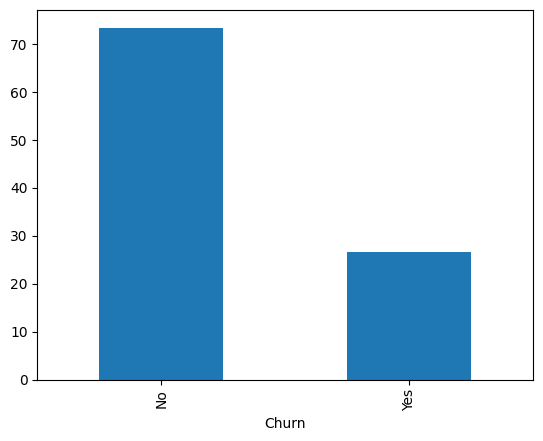

In [9]:
#Visualize customer churn
(df['Churn'].value_counts(normalize=True) * 100).plot(kind='bar')

In [10]:
df['TotalCharges'] = df['TotalCharges'].replace(" ", np.nan)

In [13]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [14]:
#Check the dataset summary
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


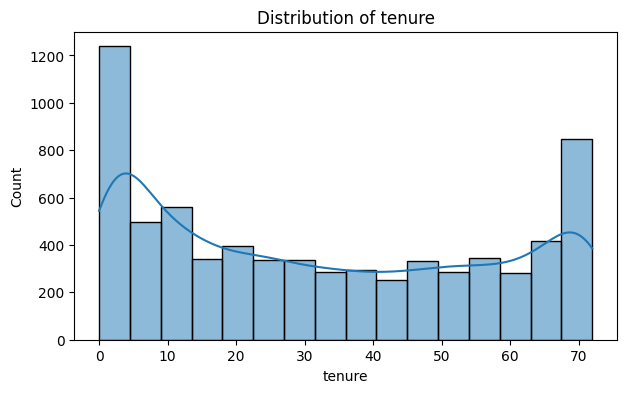

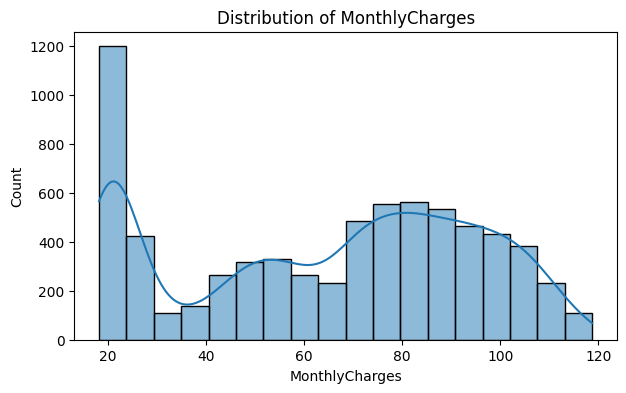

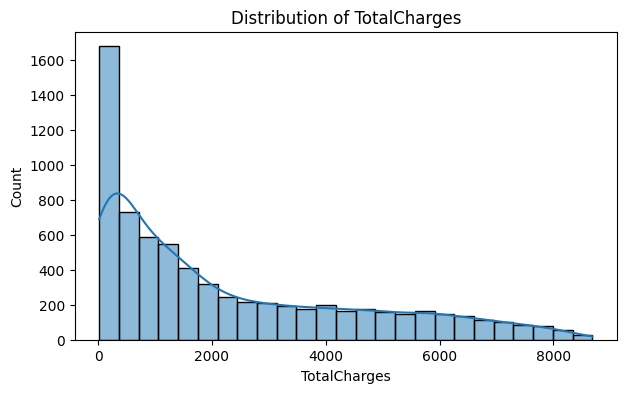

In [15]:
#Analyze numerical features
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

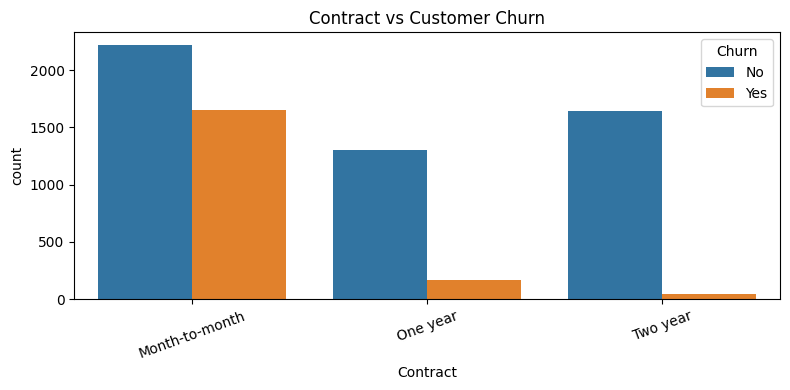

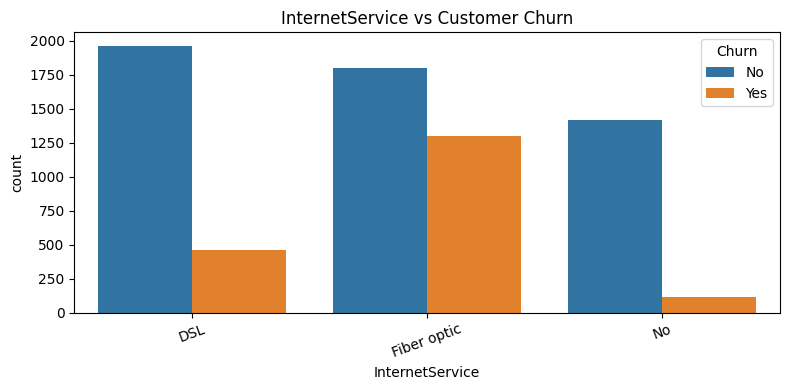

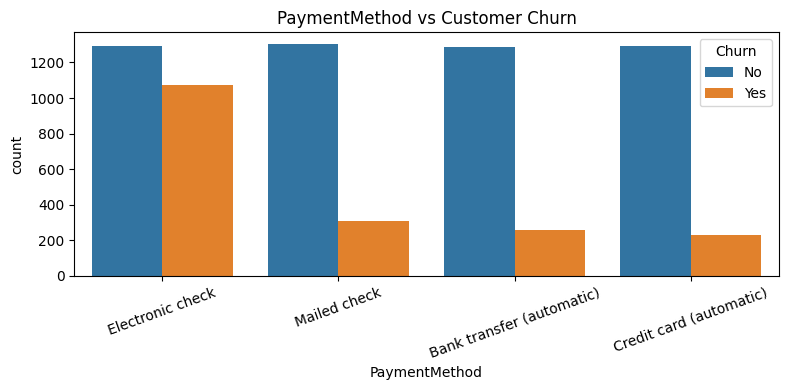

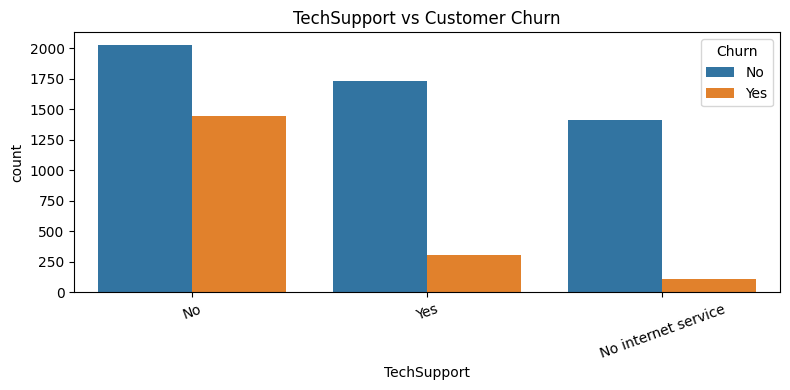

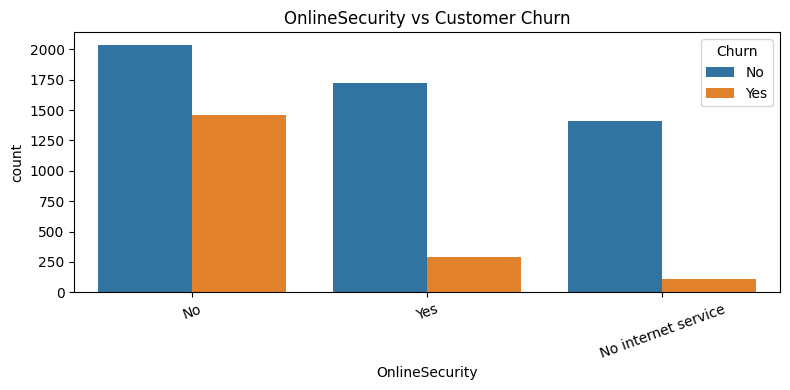

In [16]:
#Analyze churn against categorical features
categorical_cols = [
    'Contract',
    'InternetService',
    'PaymentMethod',
    'TechSupport',
    'OnlineSecurity'
]

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue='Churn')
    plt.title(f'{col} vs Customer Churn')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

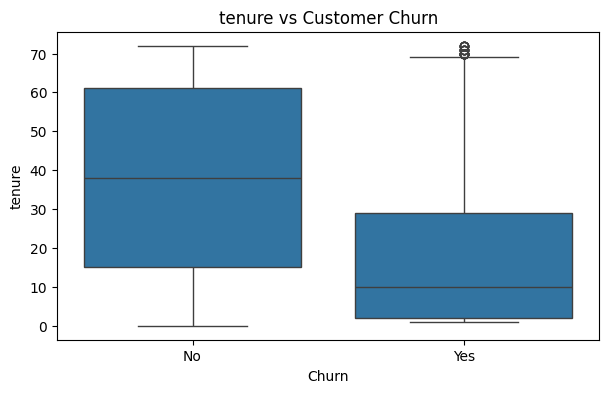

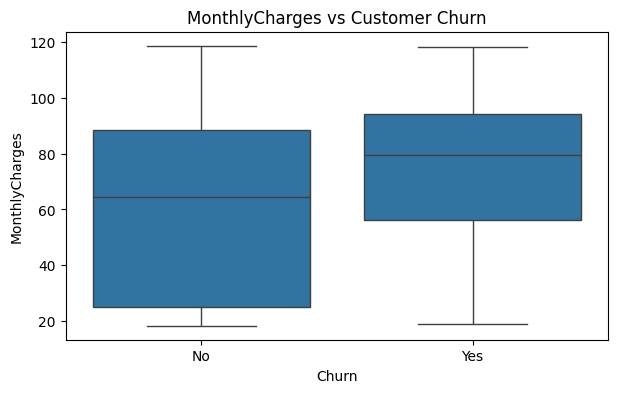

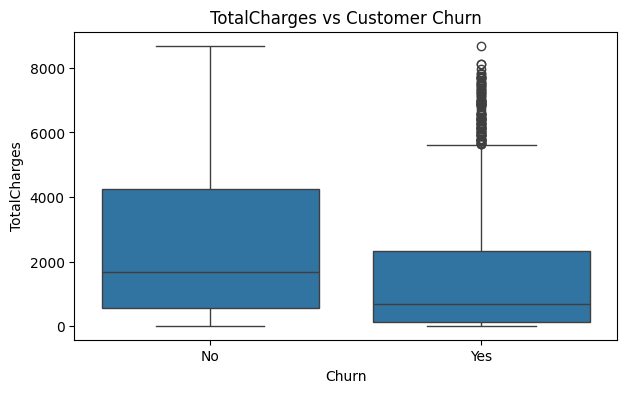

In [17]:
#Analyze numerical features against churn
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='Churn', y=col)
    plt.title(f'{col} vs Customer Churn')
    plt.show()

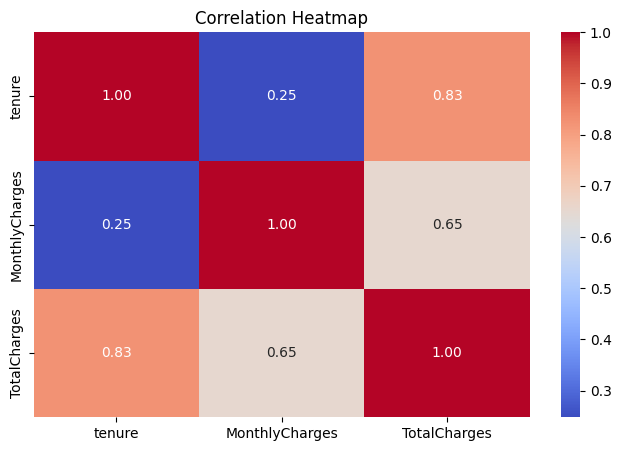

In [18]:
#Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Feature Selection

In this step, relevant features are selected from the original dataset for customer churn prediction. The `customerID` column is excluded because it is only an identifier and does not provide useful predictive information.

In [19]:
df_new = df.drop(columns=['customerID']).copy()

## Categorical Data Encoding

Categorical features contain text-based values that machine learning algorithms cannot directly process. To convert these values into numerical format, binary mapping and One-Hot Encoding techniques are used.

Binary mapping is applied to binary categorical columns, while the One-Hot Encoder class from Scikit-learn is used for categorical features containing multiple categories. This prevents the model from assuming an artificial numerical order between categories.

In [20]:
df_new.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [21]:
columns = ['gender','SeniorCitizen','Partner','Dependents','PhoneService','MultipleLines','InternetService',
          'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV',
          'StreamingMovies','Contract', 'PaperlessBilling','PaymentMethod','Churn']
for col in columns:
    print(f"{col} Unique values:",df_new[col].unique())

gender Unique values: ['Female' 'Male']
SeniorCitizen Unique values: [0 1]
Partner Unique values: ['Yes' 'No']
Dependents Unique values: ['No' 'Yes']
PhoneService Unique values: ['No' 'Yes']
MultipleLines Unique values: ['No phone service' 'No' 'Yes']
InternetService Unique values: ['DSL' 'Fiber optic' 'No']
OnlineSecurity Unique values: ['No' 'Yes' 'No internet service']
OnlineBackup Unique values: ['Yes' 'No' 'No internet service']
DeviceProtection Unique values: ['No' 'Yes' 'No internet service']
TechSupport Unique values: ['No' 'Yes' 'No internet service']
StreamingTV Unique values: ['No' 'Yes' 'No internet service']
StreamingMovies Unique values: ['No' 'Yes' 'No internet service']
Contract Unique values: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling Unique values: ['Yes' 'No']
PaymentMethod Unique values: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn Unique values: ['No' 'Yes']


## Binary Encoding

In [22]:
mapping = {
    'gender':{'Female':0, 'Male':1},
    'Partner':{'Yes':1,'No':0},
    'Dependents':{'Yes':1,'No':0},
    'PhoneService':{'Yes':1,'No':0},
    'PaperlessBilling':{'Yes':1,'No':0},
    'Churn':{'Yes':1,'No':0}
}

In [23]:
df_new = df_new.replace(mapping)

C:\Users\ZEYAN KHAN\AppData\Local\Temp\ipykernel_28332\4089363842.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_new = df_new.replace(mapping)


## One-Hot Encoding

In [24]:
categorical_cols = ['MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
    'StreamingTV','StreamingMovies','Contract','PaymentMethod']

In [25]:
encoder = OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)
encoded_data = encoder.fit_transform(df_new[categorical_cols])

In [26]:
encoded_df = pd.DataFrame(encoded_data,columns=encoder.get_feature_names_out(categorical_cols),index=df_new.index)

In [27]:
df_new = pd.concat([df_new.drop(columns=categorical_cols), encoded_df],axis=1)

In [28]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   float64
 11  Mult

## Feature and Target Selection

The encoded dataset is divided into independent and dependent variables. The independent variables (X) contain customer information and service-related features, while the dependent variable (y) represents customer churn.

The objective is to train machine learning models to predict whether a customer is likely to leave the service.

In [29]:
X = df_new.drop("Churn",axis=1)

In [30]:
y = df_new['Churn']

## Train-Test Split

The dataset is divided into training and testing sets to evaluate the performance of machine learning models on unseen data.

In this project, 80% of the data is used for training and 20% for testing. The `stratify` parameter is applied to maintain the same proportion of churn and non-churn customers in both sets. A random state of 42 is used to ensure reproducibility.

In [37]:
X_train,X_test, y_train,y_test = train_test_split(X,y,test_size=0.30,random_state=0)

## Handling Class Imbalance Using SMOTE

The Telco Customer Churn dataset contains an imbalance between customers who churn and those who do not churn. This imbalance can affect the model's ability to identify customers who are likely to leave.

To address this issue, the Synthetic Minority Over-sampling Technique (SMOTE) is applied to the training dataset. SMOTE generates synthetic samples for the minority class to balance the training data.

SMOTE is applied only to the training set to prevent data leakage and maintain an unbiased evaluation on the testing set.

In [38]:
smote = SMOTE(random_state=42)
x_train,Y_train = smote.fit_resample(X_train,y_train)

Axes(0.125,0.11;0.775x0.77)


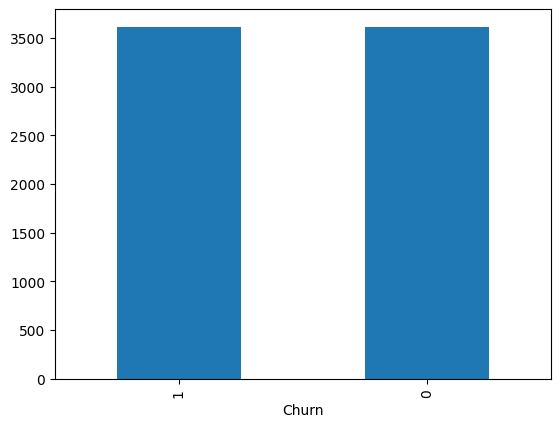

In [39]:
print(Y_train.value_counts().plot(kind='bar'))

## Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In this project, Random Forest is used to predict customer churn based on customer demographics, account information, and subscribed services.

To handle class imbalance, the `class_weight='balanced'` parameter is used. Hyperparameter tuning and cross-validation are performed to identify the best model configuration using ROC-AUC as the evaluation metric.

In [40]:
rf = RandomForestClassifier(n_estimators=350,max_depth=None,criterion = 'log_loss',random_state=42)
rf.fit(x_train,Y_train)

,n_estimators,350
,criterion,'log_loss'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
YPred = rf.predict(X_test)

## RandomForestClassifier Model Evaluation

Accuracy: 0.7789872219592996
Recall: 0.5298372513562387
f1 score: 0.5565052231718899
precision: 0.586
Report:               precision    recall  f1-score   support

           0       0.84      0.87      0.85      1560
           1       0.59      0.53      0.56       553

    accuracy                           0.78      2113
   macro avg       0.71      0.70      0.70      2113
weighted avg       0.77      0.78      0.78      2113



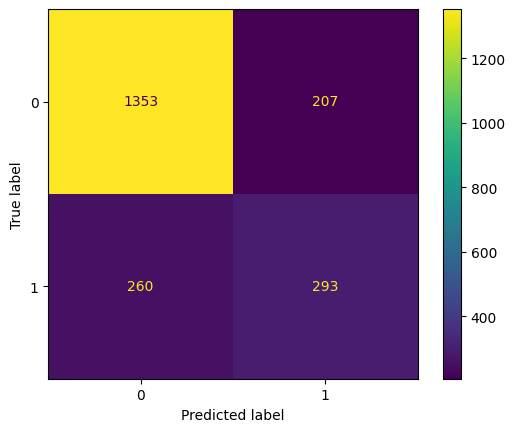

In [42]:
print('Accuracy:',accuracy_score(y_test,YPred))
print('Recall:',recall_score(y_test,YPred))
print('f1 score:',f1_score(y_test,YPred))
print('precision:',precision_score(y_test,YPred))
print('Report:',classification_report(y_test,YPred))

confuse = confusion_matrix(y_test, YPred)

disp = ConfusionMatrixDisplay(confusion_matrix=confuse)
disp.plot()

## XGBoost Classifier with Hyperparameter Tuning

XGBoost (Extreme Gradient Boosting) is an ensemble machine learning algorithm that builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees.

In this project, XGBoost is used to predict customer churn. SMOTE is integrated into the training pipeline to handle class imbalance. GridSearchCV with 5-fold cross-validation is used to find the best hyperparameters, with ROC-AUC as the optimization metric.

In [43]:
xgb_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ))
])

In [ ]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


In [ ]:
print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(xgb_grid.best_score_)

## XGBoost Model Evaluation

The best XGBoost model obtained through GridSearchCV is evaluated on the test dataset. The model's performance is measured using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. A confusion matrix is also used to examine correct and incorrect churn predictions.

In [ ]:
best_xgb = xgb_grid.best_estimator_

# Make predictions
y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("XGBoost Model Performance")
print("-------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()
best_xgb = xgb_grid.best_estimator_

# Make predictions
y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("XGBoost Model Performance")
print("-------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

## ROC Curve Comparison: Random Forest vs XGBoost

The Receiver Operating Characteristic (ROC) curve compares the classification performance of Random Forest and XGBoost at different classification thresholds. The Area Under the Curve (AUC) measures how effectively each model distinguishes between churn and non-churn customers. A higher AUC indicates better class discrimination.

In [ ]:
rf_prob = rf.predict_proba(X_test)[:, 1]

# XGBoost probabilities
xgb_prob = best_xgb.predict_proba(X_test)[:, 1]

# Calculate ROC curves
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

# Calculate AUC scores
rf_auc = roc_auc_score(y_test, rf_prob)
xgb_auc = roc_auc_score(y_test, xgb_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {xgb_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Random Forest vs XGBoost")
plt.legend()
plt.grid()
plt.show()

print("Random Forest ROC-AUC:", rf_auc)
print("XGBoost ROC-AUC:", xgb_auc)

## Feature Importance Analysis

Feature importance analysis identifies the variables that contribute most to the predictions made by the machine learning models. In this section, the top 10 important features are extracted from Random Forest and XGBoost to understand which customer characteristics have the greatest influence on churn prediction.

In [ ]:
# Random Forest Feature Importance
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

rf_importance = rf_importance.sort_values(by='Importance', ascending=False).head(10)

# XGBoost Feature Importance
xgb_model = best_xgb.named_steps['classifier']

xgb_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
})
xgb_importance = xgb_importance.sort_values(
    by='Importance', ascending=False
).head(10)

# Display Top 10 Features
print("Top 10 Features - Random Forest")
display(rf_importance)

print("Top 10 Features - XGBoost")
display(xgb_importance)

# Plot Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    rf_importance['Feature'],
    rf_importance['Importance']
)
axes[0].set_title("Random Forest - Top 10 Features")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()

axes[1].barh(
    xgb_importance['Feature'],
    xgb_importance['Importance']
)
axes[1].set_title("XGBoost - Top 10 Features")
axes[1].set_xlabel("Importance")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()